In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#to ignore warnings

import warnings
warnings.filterwarnings('ignore')

In [2]:
path = "../data/raw" # Data directory

bay_dist_data = pd.read_csv(os.path.join(path, "distances_bay_2017.csv"))
la_dist_data = pd.read_csv(os.path.join(path, "distances_la_2012.csv"))
la_sensor_data = pd.read_csv(os.path.join(path, "METR-LA.csv"))
bay_sensor_data = pd.read_csv(os.path.join(path, "PEMS-BAY.csv"))
bay_sensor_metadata = pd.read_csv(os.path.join(path, "graph_sensor_locations_bay.csv"))
la_sensor_metadata = pd.read_csv(os.path.join(path, "graph_sensor_locations.csv"))

In [3]:
la_sensor_data = la_sensor_data.rename(columns={"Unnamed: 0": "timestamp"})
la_sensor_data.head()

,timestamp,773869,767541,767542,717447,717446,717445,773062,767620,737529,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
0,2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
1,2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2,2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
3,2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
4,2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


In [4]:
la_sensor_data.tail()

,timestamp,773869,767541,767542,717447,717446,717445,773062,767620,737529,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
34267,2012-06-27 23:35:00,65.000000,65.888889,68.555556,61.666667,0.0,54.555556,62.444444,63.333333,59.222222,...,52.888889,69.000000,65.111111,55.666667,66.333333,62.444444,66.777778,64.888889,69.666667,62.333333
34268,2012-06-27 23:40:00,61.375000,65.625000,66.500000,62.750000,0.0,50.500000,62.000000,67.000000,65.250000,...,54.000000,69.250000,60.125000,60.500000,67.250000,59.375000,66.000000,61.250000,69.000000,62.000000
34269,2012-06-27 23:45:00,67.000000,59.666667,69.555556,61.000000,0.0,44.777778,64.222222,63.777778,59.777778,...,51.333333,67.888889,64.333333,57.000000,66.000000,62.666667,68.666667,63.333333,67.444444,61.222222
34270,2012-06-27 23:50:00,66.750000,62.250000,66.000000,59.625000,0.0,53.000000,64.285714,64.125000,60.875000,...,51.125000,69.375000,61.625000,60.500000,65.625000,66.375000,69.500000,63.000000,67.875000,63.500000
34271,2012-06-27 23:55:00,65.111111,66.888889,66.777778,61.222222,0.0,49.555556,65.777778,65.111111,63.000000,...,56.000000,67.444444,64.888889,60.888889,64.222222,66.444444,68.444444,63.555556,68.666667,61.777778


In [5]:
print(la_dist_data.shape)
display(la_dist_data.sample(10))

(295374, 3)


,from,to,cost
28102,1204944,1211343,11594.0
97159,716471,718326,7830.4
36622,1205583,1203536,10398.1
199881,767541,767759,6265.5
97272,716481,769248,6677.9
176603,761455,769228,4528.7
278571,818612,823289,4714.4
58519,1211752,1204798,5973.8
56045,1211625,1211629,1360.0
153364,718045,717055,9236.9


In [6]:
la_sensor_data.shape

(34272, 208)

In [7]:
la_sensor_metadata.info()
display(la_sensor_metadata.head())

<class 'pandas.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   index      207 non-null    int64  
 1   sensor_id  207 non-null    int64  
 2   latitude   207 non-null    float64
 3   longitude  207 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 6.6 KB


,index,sensor_id,latitude,longitude
0,0,773869,34.15497,-118.31829
1,1,767541,34.11621,-118.23799
2,2,767542,34.11641,-118.23819
3,3,717447,34.07248,-118.26772
4,4,717446,34.07142,-118.26572


## 1. Dataset Overview

METR-LA is a traffic speed forecasting dataset collected from 207 highway loop detectors in Los Angeles County. It was used as a benchmark in the DCRNN traffic forecasting work. The measurements are recorded at 5-minute intervals over roughly four months.

| Property               | METR-LA                   |
| ---------------------- | ------------------------- |
| Location               | Los Angeles, California   |
| Sensors                | **207**                   |
| Time interval          | **5 minutes**             |
| Time period            | March 1 – June 28, 2012   |
| Time steps             | **34,272**                |
| Main measurement       | **Traffic speed**         |
| Number of observations | 34,272 × 207              |
| Spatial information    | Sensor latitude/longitude |
| Typical task           | Traffic-speed forecasting |




## 1.1 Visualizing Sensor Locations

In [8]:
import folium

center_lat = la_sensor_metadata["latitude"].mean()
center_lon = la_sensor_metadata["longitude"].mean()

API_KEY = "cb1_3wi1_1_961acd3a5616401f43c3e659"

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11,
    tiles=None
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Street Map",
    overlay=False,
    control=False,
    width="100px",
    height="600px",
).add_to(m)

for _, row in la_sensor_metadata.iterrows():

    # Sensor point
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=5,
        popup=folium.Popup(
            f"""
            <b>Sensor ID:</b> {row['sensor_id']}<br>
            <b>Latitude:</b> {row['latitude']:.6f}<br>
            <b>Longitude:</b> {row['longitude']:.6f}
            """,
            max_width=250
        ),
        tooltip=f"Sensor {row['sensor_id']}",
        fill=True,
        fill_opacity=0.8
    ).add_to(m)

    # Sensor ID label
    # folium.Marker(
    #     location=[row["latitude"], row["longitude"]],
    #     icon=folium.DivIcon(
    #         html=f"""
    #         <div style="
    #             font-size: 10px;
    #             font-weight: bold;
    #             color: black;
    #             background-color: transparent;

    #         ">
    #             {row["sensor_id"]}
    #         </div>
    #         """
    #     )
    # ).add_to(m)

m

# EDA

In [9]:
la_sensor_data.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 34272 entries, 0 to 34271
Data columns (total 208 columns):
 #    Column     Non-Null Count  Dtype  
---   ------     --------------  -----  
 0    timestamp  34272 non-null  str    
 1    773869     34272 non-null  float64
 2    767541     34272 non-null  float64
 3    767542     34272 non-null  float64
 4    717447     34272 non-null  float64
 5    717446     34272 non-null  float64
 6    717445     34272 non-null  float64
 7    773062     34272 non-null  float64
 8    767620     34272 non-null  float64
 9    737529     34272 non-null  float64
 10   717816     34272 non-null  float64
 11   765604     34272 non-null  float64
 12   767471     34272 non-null  float64
 13   716339     34272 non-null  float64
 14   773906     34272 non-null  float64
 15   765273     34272 non-null  float64
 16   716331     34272 non-null  float64
 17   771667     34272 non-null  float64
 18   716337     34272 non-null  float64
 19   769953     34272 non-null  float64

In [10]:
la_sensor_data.describe().T

,count,mean,std,min,25%,50%,75%,max
773869,34272.0,54.631359,22.619199,0.0,60.364583,64.888889,66.875000,70.0
767541,34272.0,60.452789,15.970239,0.0,63.000000,65.000000,66.375000,70.0
767542,34272.0,60.726120,18.313353,0.0,65.444444,67.375000,68.444444,70.0
717447,34272.0,49.524287,15.843261,0.0,50.333333,53.875000,58.125000,70.0
717446,34272.0,46.079798,19.350345,0.0,34.666667,46.000000,64.500000,70.0
...,...,...,...,...,...,...,...,...
717592,34272.0,56.915083,18.260438,0.0,60.222222,63.000000,64.750000,70.0
717595,34272.0,62.484679,16.959238,0.0,65.888889,67.625000,68.625000,70.0
772168,34272.0,54.697381,16.303651,0.0,50.125000,61.125000,64.444444,70.0
718141,34272.0,58.920210,19.080474,0.0,62.888889,66.125000,67.750000,70.0


### **insights**
- Minimium speed for traffic is 0.0. this can mean no traffic is recorded by the sensor at that period.
- Maximium recorded speed for traffic is 70 mph.


## 2.1 Creating Features

In [11]:
from datetime import date, time

la_sensor_data["timestamp"] = pd.to_datetime(la_sensor_data["timestamp"])

la_sensor_data["hour"] = la_sensor_data["timestamp"].dt.hour
la_sensor_data["day_of_week"] = la_sensor_data["timestamp"].dt.dayofweek
la_sensor_data["month"] = la_sensor_data["timestamp"].dt.month
la_sensor_data["is_weekend"] = (la_sensor_data["day_of_week"] >= 5).astype(int)

In [12]:
print(la_sensor_data.shape)
display(la_sensor_data.sample(10)[["timestamp", "hour", "day_of_week", "month", "is_weekend"]])

(34272, 212)


,timestamp,hour,day_of_week,month,is_weekend
9379,2012-04-02 13:35:00,13,0,4,0
27609,2012-06-04 20:45:00,20,0,6,0
9121,2012-04-01 16:05:00,16,6,4,1
288,2012-03-02 00:00:00,0,4,3,0
28832,2012-06-09 02:40:00,2,5,6,1
13580,2012-04-17 03:40:00,3,1,4,0
7746,2012-03-27 21:30:00,21,1,3,0
23427,2012-05-21 08:15:00,8,0,5,0
17122,2012-04-29 10:50:00,10,6,4,1
16121,2012-04-25 23:25:00,23,2,4,0


## 2.2 Univariant Analysis

In [13]:
cat_cols=la_sensor_data.select_dtypes(include=['object']).columns
num_cols = la_sensor_data.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
Index([], dtype='str')
Numerical Variables:
['773869', '767541', '767542', '717447', '717446', '717445', '773062', '767620', '737529', '717816', '765604', '767471', '716339', '773906', '765273', '716331', '771667', '716337', '769953', '769402', '769403', '769819', '769405', '716941', '717578', '716960', '717804', '767572', '767573', '773012', '773013', '764424', '769388', '716328', '717819', '769941', '760987', '718204', '718045', '769418', '768066', '772140', '773927', '760024', '774012', '774011', '767609', '769359', '760650', '716956', '769831', '761604', '717495', '716554', '773953', '767470', '716955', '764949', '773954', '767366', '769444', '773939', '774067', '769443', '767750', '767751', '767610', '773880', '764766', '717497', '717490', '717491', '717492', '717493', '765176', '717498', '717499', '765171', '718064', '718066', '765164', '769431', '769430', '717610', '767053', '767621', '772596', '772597', '767350', '767351', '716571', '773023', '767585', '7

773869
Skew : -1.74


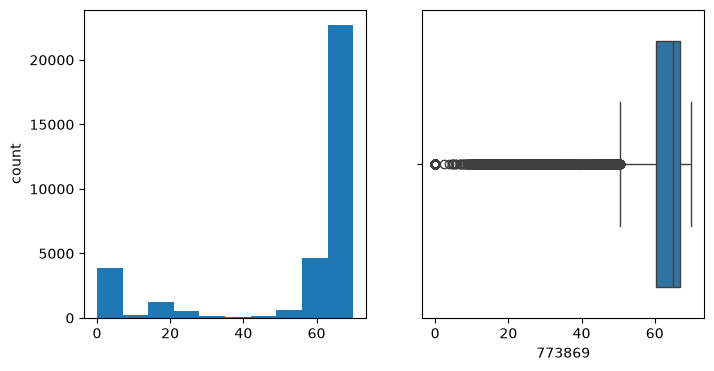

767541
Skew : -3.39


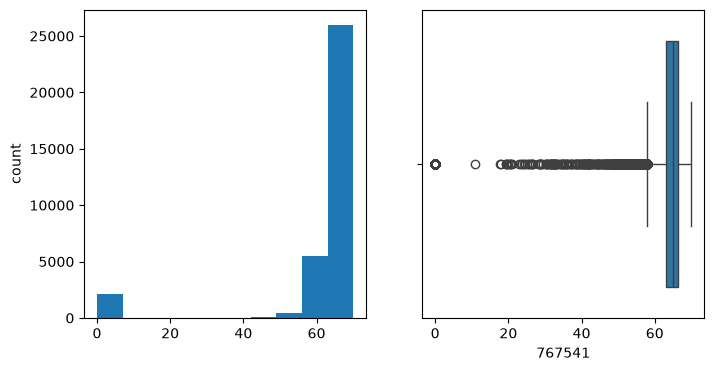

767542
Skew : -2.62


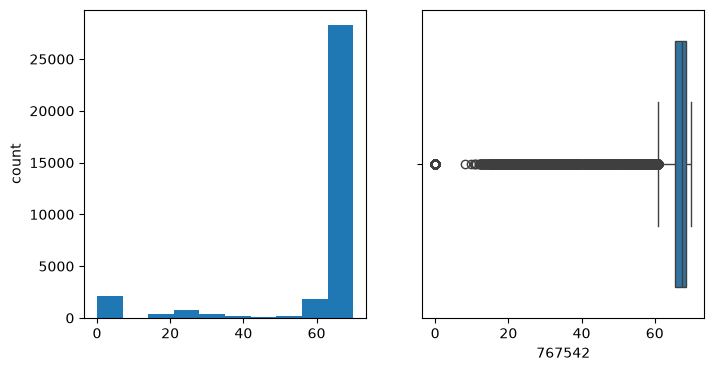

717447
Skew : -2.16


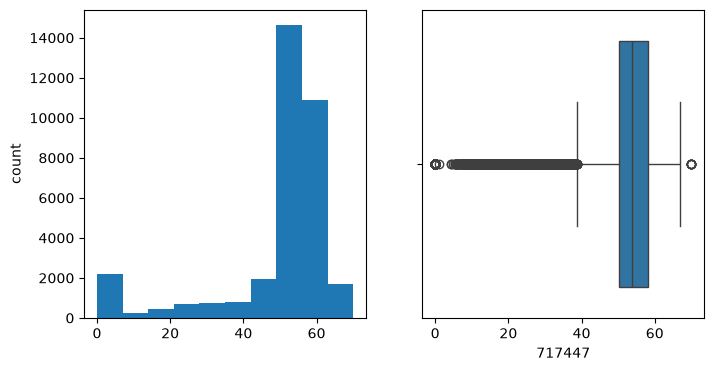

717446
Skew : -0.79


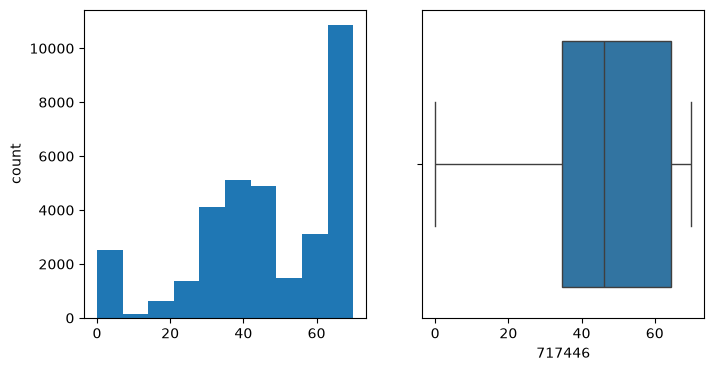

In [14]:
for i in range(5):
    col = num_cols[i]
    print(col)
    print('Skew :', round(la_sensor_data[col].skew(), 2))
    plt.figure(figsize = (8, 4))
    plt.subplot(1, 2, 1)
    la_sensor_data[col].hist(grid=False)
    plt.ylabel('count')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=la_sensor_data[col])
    plt.show()

In [15]:
skewness = list(la_sensor_data[num_cols].skew())
print(f'Avg Skewness: {sum(skewness) / len(skewness)}')

min_speed = list(la_sensor_data[num_cols].min())
max_speed = list(la_sensor_data[num_cols].max())
print(f'Avg Minimium Speed: {sum(min_speed) / len(min_speed)}')
print(f'Avg Maximium Speed: {sum(max_speed) / len(max_speed)}')

Avg Skewness: -1.9858566113263807
Avg Minimium Speed: 0.014218009478672985
Avg Maximium Speed: 68.74757391108102


- Most of the data is left skewed. That, means traffic jams and empty roads are not very common.
- Most of the time traffic speed is between 40 mph to 70 mph.

## 2.3 Bivariant Analysis


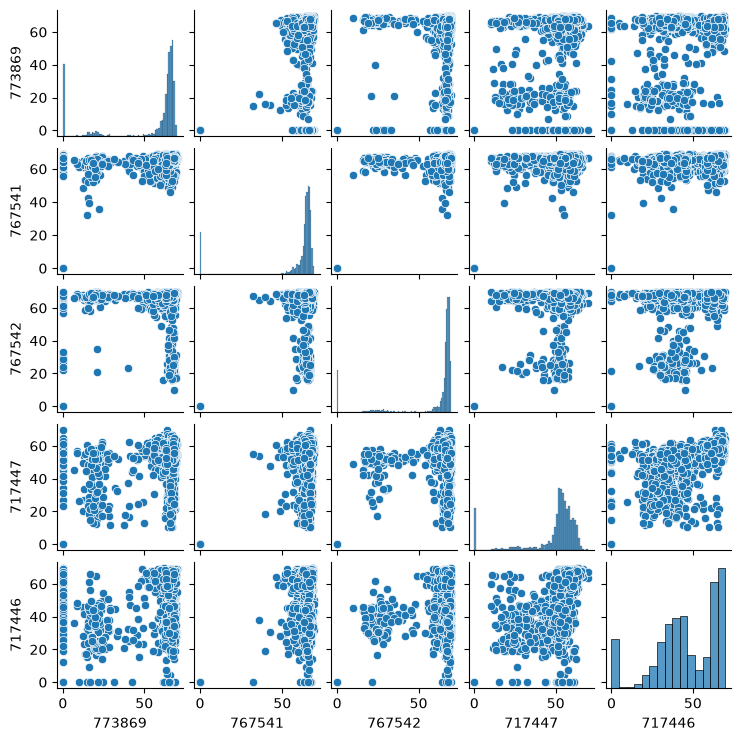

In [16]:
sns.pairplot(data=la_sensor_data[num_cols[:5]].sample(2000, random_state=42), height=1.5, aspect=1)
plt.show()

In [17]:
# Start again from  bivariant analysis
# Temporal autocorrelation — most important
# Does speed(t-5 min) help predict speed(t)?
# Cross-sensor correlation — important
# Does sensor A help predict sensor B?
# Time-of-day patterns — important
# Do speeds systematically change during morning/evening periods?
# Missing values / zero-speed behavior — important
# Pairplot — useful visualization, but secondary.